# Datenbereinigung der Mietinserate

**Input:** `data/data_processed/flatfox_rentals_zentralschweiz.csv` (aus `data_engineering_real_estate.ipynb`: zusammengeführte Erhebungen, Gemeindezuordnung, Gemeindeindikatoren)

**Output:**
- `data/data_processed/flatfox_rentals_clean.csv` – bereinigte Analysestichprobe
- `data/data_processed/flatfox_rentals_excluded.csv` – alle entfernten Inserate mit Grund (zur Dokumentation)

**Zielgrösse:** monatliche **Nettomiete** (gemäss Feasibility Study) und daraus die Nettomiete pro m².

Das Notebook folgt den sechs Pflichtschritten der Projektbeschreibung:

1. Fehlende Werte und Duplikate
2. Datentypen
3. Wertebereiche (Plausibilität)
4. Ausreisser
5. Anreicherung mit zusätzlichen Spalten
6. Format für die Analyse

Vorab wird die Stichprobe auf Mietwohnungen eingegrenzt, da die Forschungsfragen Wohnungen betreffen.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "scripts" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "data_processed"
INPUT_FILE = DATA_DIR / "flatfox_rentals_zentralschweiz.csv"
OUTPUT_FILE = DATA_DIR / "flatfox_rentals_clean.csv"
EXCLUDED_FILE = DATA_DIR / "flatfox_rentals_excluded.csv"

CENTRAL_CANTONS = ["LU", "UR", "SZ", "OW", "NW", "ZG"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv(INPUT_FILE, low_memory=False)
print(f"Eingelesen: {len(raw)} Inserate, {raw.shape[1]} Spalten")

Eingelesen: 513 Inserate, 156 Spalten


In [ ]:
excluded = []
log = [("Ausgangslage", len(raw))]


def exclude(df, mask, step, reason):
    # Entfernt Zeilen gemäss Maske und protokolliert sie.
    mask = mask.fillna(False)
    removed = df.loc[mask, ["pk", "gemeinde_name", "kanton_geo", "object_type", "surface_living", "number_of_rooms"]].copy()
    removed["step"] = step
    removed["reason"] = reason
    excluded.append(removed)
    kept = df.loc[~mask].copy()
    log.append((f"{step}: {reason}", len(kept)))
    print(f"{step} – {reason}: {mask.sum()} entfernt, {len(kept)} verbleibend")
    return kept

## Eingrenzung auf Mietwohnungen

Der Input enthält alle Mietobjekte der Kategorien *Wohnung* und *Haus*. Darunter sind auch WG-Zimmer (`SINGLE_ROOM`) und Einfamilienhäuser. Diese sind nicht mit Wohnungen vergleichbar und werden entfernt.

In [3]:
display(raw["object_type"].value_counts().rename("Anzahl").to_frame())

APARTMENT_TYPES = ["APARTMENT", "ATTIC_FLAT", "DUPLEX", "ROOF_FLAT", "STUDIO", "LOFT", "TERRACE_FLAT"]

df = exclude(raw, ~raw["object_type"].isin(APARTMENT_TYPES), "0 Eingrenzung", "keine Wohnung (WG-Zimmer, Haus)")

,Anzahl
object_type,
APARTMENT,440
SINGLE_ROOM,17
SINGLE_HOUSE,15
ATTIC_FLAT,13
DUPLEX,12
ROOF_FLAT,5
STUDIO,3
LOFT,2
FARM_HOUSE,2


0 Eingrenzung – keine Wohnung (WG-Zimmer, Haus): 36 entfernt, 477 verbleibend


## Fehlende Werte und Duplikate

### Nettomiete
Die Nettomiete ist nicht bei allen Inseraten direkt angegeben. Wo sie fehlt, aber Bruttomiete und Nebenkosten vorhanden sind, wird sie berechnet: **Nettomiete = Bruttomiete − Nebenkosten**. Inserate, bei denen sich keine Nettomiete bestimmen lässt, werden entfernt. Fehlende Werte werden nicht geschätzt, weil die Miete unsere Zielgrösse ist.

In [4]:
key_columns = ["rent_net", "rent_gross", "rent_charges", "surface_living", "number_of_rooms",
               "floor", "year_built", "year_renovated", "latitude", "longitude", "gemeinde_bfs"]
missing = pd.DataFrame({
    "fehlend": df[key_columns].isna().sum(),
    "fehlend (%)": df[key_columns].isna().mean().mul(100).round(1),
})
missing

,fehlend,fehlend (%)
rent_net,181,37.9
rent_gross,76,15.9
rent_charges,135,28.3
surface_living,0,0.0
number_of_rooms,0,0.0
floor,99,20.8
year_built,241,50.5
year_renovated,376,78.8
latitude,0,0.0
longitude,0,0.0


In [5]:
df["rent_net_source"] = np.where(df["rent_net"].notna(), "angegeben", None)
derived = df["rent_net"].isna() & df["rent_gross"].notna() & df["rent_charges"].notna()
df.loc[derived, "rent_net"] = df.loc[derived, "rent_gross"] - df.loc[derived, "rent_charges"]
df.loc[derived, "rent_net_source"] = "berechnet (brutto − Nebenkosten)"

print(df["rent_net_source"].value_counts(dropna=False))

df = exclude(df, df["rent_net"].isna(), "1 Fehlende Werte", "keine Nettomiete bestimmbar")

rent_net_source
angegeben                           296
None                                129
berechnet (brutto − Nebenkosten)     52
Name: count, dtype: int64
1 Fehlende Werte – keine Nettomiete bestimmbar: 129 entfernt, 348 verbleibend


Wie stark die Stichprobe durch die Nettomiete pro Kanton schrumpft, ist wichtig für die Interpretation (besonders für Uri, Obwalden und Nidwalden):

In [6]:
before = raw[raw["object_type"].isin(APARTMENT_TYPES)]["kanton_geo"].value_counts()
after = df["kanton_geo"].value_counts()
pd.DataFrame({"Wohnungen": before, "mit Nettomiete": after}).reindex(CENTRAL_CANTONS).fillna(0).astype(int)

,Wohnungen,mit Nettomiete
kanton_geo,,
LU,334,252
UR,9,3
SZ,67,50
OW,12,7
NW,6,5
ZG,49,31


### Gemeindeindikatoren
Die Sozialhilfequote fehlt für einige kleine Gemeinden. Diese Inserate werden nicht entfernt, weil alle anderen Angaben vorhanden sind. In Analysen mit der Sozialhilfequote fallen sie automatisch weg.

In [7]:
indicator_columns = ["income_median_chf", "population_growth_pct", "population_density_productive",
                     "household_size_mean", "vacancy_rate_pct", "social_assistance_rate_pct",
                     "population_age65plus_pct", "employment_per_100_residents",
                     "new_dwellings_per_1000_residents", "single_family_buildings_pct",
                     "foreign_population_pct", "net_migration_per_1000_residents"]
df[indicator_columns].isna().sum().rename("fehlende Werte").to_frame()

,fehlende Werte
income_median_chf,0
population_growth_pct,0
population_density_productive,0
household_size_mean,0
vacancy_rate_pct,0
social_assistance_rate_pct,2
population_age65plus_pct,0
employment_per_100_residents,0
new_dwellings_per_1000_residents,0
single_family_buildings_pct,0


### Duplikate
Die Inserat-ID (`pk`) ist nach dem Zusammenführen bereits eindeutig. Dieselbe Wohnung kann aber unter einer neuen ID erneut inseriert werden. Als Duplikat gilt ein Inserat, wenn Gemeinde, Strasse, Fläche, Zimmerzahl, Stockwerk und Nettomiete identisch sind. Behalten wird jeweils das zuerst erfasste Inserat.

Hinweis: Identische Wohnungen im selben Neubau würden dadurch ebenfalls zusammengefasst. Das nehmen wir in Kauf, weil sie keine zusätzliche Information über Preisunterschiede liefern.

In [8]:
assert df["pk"].is_unique, "pk ist nicht eindeutig"

dup_key = ["gemeinde_bfs", "street", "surface_living", "number_of_rooms", "floor", "rent_net"]
df = df.sort_values("first_seen_at")
is_dup = df.duplicated(subset=dup_key, keep="first")

display(df[df.duplicated(subset=dup_key, keep=False)]
        .sort_values(dup_key)[["pk", "gemeinde_name", "street", "surface_living", "number_of_rooms", "rent_net", "first_seen_at"]])

df = exclude(df, is_dup, "1 Duplikate", "gleiche Wohnung unter neuer ID")

,pk,gemeinde_name,street,surface_living,number_of_rooms,rent_net,first_seen_at
408,86456070,Kriens,Schachenstrasse 45,77.0,4.5,1490.0,2026-10-18T10:31:04.510890Z
510,86479687,Kriens,Schachenstrasse 45,77.0,4.5,1490.0,2026-10-24T08:49:29.632207Z
231,86397059,Luzern,Auf Anfrage,440.0,8.0,6500.0,2026-10-18T10:06:11.875376Z
488,86472738,Luzern,Auf Anfrage,440.0,8.0,6500.0,2026-10-22T15:35:15.050865Z
24,85820071,Luzern,Weinmarkt 11,71.0,2.5,2360.0,2026-10-18T10:06:11.875376Z
500,86476892,Luzern,Weinmarkt 11,71.0,2.5,2360.0,2026-10-23T12:25:48.028947Z
313,86428626,Ruswil,Wolhuserstrasse 13,141.0,4.5,2300.0,2026-10-18T10:31:04.510890Z
450,86463610,Ruswil,Wolhuserstrasse 13,141.0,4.5,2300.0,2026-10-19T15:11:08.866230Z
291,86422743,Sursee,Auf Anfrage,106.0,4.5,2450.0,2026-10-18T10:31:04.510890Z
292,86422791,Sursee,Auf Anfrage,106.0,4.5,2450.0,2026-10-18T10:31:04.510890Z


1 Duplikate – gleiche Wohnung unter neuer ID: 8 entfernt, 340 verbleibend


## Datentypen

Beim Einlesen aus CSV erkennt pandas nicht alle Typen korrekt (z. B. Zeitstempel als Text, IDs als Kommazahl). Wir setzen sie explizit.

In [9]:
print("Vorher:")
check_columns = ["pk", "gemeinde_bfs", "number_of_rooms", "floor", "year_built", "first_seen_at",
                 "published", "is_furnished", "attribute_reported_lift", "kanton_geo", "object_type"]
display(df[check_columns].dtypes.rename("dtype").to_frame())

df["pk"] = df["pk"].astype("int64")
df["gemeinde_bfs"] = df["gemeinde_bfs"].astype("Int64")

for col in ["floor", "year_built", "year_renovated"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")

for col in ["rent_net", "rent_gross", "rent_charges", "surface_living", "number_of_rooms"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").astype("float64")

for col in ["first_seen_at", "last_seen_at"]:
    df[col] = pd.to_datetime(df[col], utc=True)
df["published"] = pd.to_datetime(df["published"], utc=True, format="ISO8601")

bool_columns = ["is_furnished", "is_temporary"] + [c for c in df.columns if c.startswith("attribute_reported_")]
for col in bool_columns:
    df[col] = df[col].astype("boolean")

for col in ["kanton_geo", "object_type", "rent_net_source"]:
    df[col] = df[col].astype("category")

print("Nachher:")
display(df[check_columns].dtypes.rename("dtype").to_frame())

Vorher:


,dtype
pk,int64
gemeinde_bfs,int64
number_of_rooms,float64
floor,float64
year_built,float64
first_seen_at,object
published,object
is_furnished,bool
attribute_reported_lift,bool
kanton_geo,object


Nachher:


,dtype
pk,int64
gemeinde_bfs,Int64
number_of_rooms,float64
floor,Int64
year_built,Int64
first_seen_at,"datetime64[ns, UTC]"
published,"datetime64[ns, UTC]"
is_furnished,boolean
attribute_reported_lift,boolean
kanton_geo,category


## Wertebereiche

Wir prüfen, ob die Werte in einem plausiblen Bereich liegen. Die Grenzen sind bewusst grosszügig gewählt; sie sollen nur offensichtliche Erfassungsfehler erkennen. Ungewöhnliche, aber mögliche Werte werden im nächsten Schritt (Ausreisser) behandelt.

| Variable | Plausibler Bereich | Begründung | Behandlung |
|---|---|---|---|
| Wohnfläche | ≥ 20 m² | Kleinere Einheiten sind Zimmer, keine Wohnungen | Inserat entfernen |
| Fläche pro Zimmer | ≥ 8 m² | Kleinere Werte deuten auf Fehleingabe hin | Inserat entfernen |
| Nettomiete | > 0 und > Nebenkosten | Nebenkosten höher als Miete ist unplausibel | Inserat entfernen |
| Zimmerzahl | 1–10 | | Inserat entfernen |
| Stockwerk | −1 bis 30 | Höchste Wohngebäude der Region haben < 30 Stockwerke; 99 ist ein Platzhalter | Wert auf fehlend setzen |
| Baujahr | 1500 bis 2027 | Altstadtgebäude bis Neubau in Planung | Wert auf fehlend setzen |
| Koordinaten | innerhalb der Zentralschweiz | wurde bereits bei der Gemeindezuordnung geprüft | – |

Bei Stockwerk und Baujahr setzen wir nur den Wert auf fehlend, weil diese Variablen nicht zentral sind und der Rest des Inserats brauchbar ist.

In [10]:
display(df[["surface_living", "number_of_rooms", "rent_net", "rent_charges", "floor", "year_built"]]
        .describe().T[["min", "25%", "50%", "75%", "max"]])

df = exclude(df, df["surface_living"] < 20, "3 Wertebereich", "Wohnfläche < 20 m²")
df = exclude(df, df["surface_living"] / df["number_of_rooms"] < 8, "3 Wertebereich", "Fläche pro Zimmer < 8 m²")
df = exclude(df, (df["rent_net"] <= 0) | (df["rent_charges"] >= df["rent_net"]), "3 Wertebereich", "Nettomiete ≤ 0 oder ≤ Nebenkosten")
df = exclude(df, ~df["number_of_rooms"].between(1, 10), "3 Wertebereich", "Zimmerzahl ausserhalb 1–10")

bad_floor = ~df["floor"].between(-1, 30) & df["floor"].notna()
bad_year = ~df["year_built"].between(1500, 2027) & df["year_built"].notna()
print(f"Stockwerk auf fehlend gesetzt: {bad_floor.sum()} (Werte: {sorted(df.loc[bad_floor, 'floor'].tolist())})")
print(f"Baujahr auf fehlend gesetzt: {bad_year.sum()}")
df.loc[bad_floor, "floor"] = pd.NA
df.loc[bad_year, "year_built"] = pd.NA

,min,25%,50%,75%,max
surface_living,10.0,67.0,83.5,105.0,440.0
number_of_rooms,1.0,2.5,3.5,4.5,8.0
rent_net,250.0,1610.0,1985.0,2496.25,6970.0
rent_charges,50.0,180.0,240.0,290.0,2900.0
floor,-1.0,1.0,2.0,3.0,99.0
year_built,1714.0,1966.5,2013.0,2024.0,2027.0


3 Wertebereich – Wohnfläche < 20 m²: 3 entfernt, 337 verbleibend
3 Wertebereich – Fläche pro Zimmer < 8 m²: 0 entfernt, 337 verbleibend
3 Wertebereich – Nettomiete ≤ 0 oder ≤ Nebenkosten: 1 entfernt, 336 verbleibend
3 Wertebereich – Zimmerzahl ausserhalb 1–10: 0 entfernt, 336 verbleibend
Stockwerk auf fehlend gesetzt: 2 (Werte: [33, 99])
Baujahr auf fehlend gesetzt: 0


## Ausreisser

Für die Ausreisser betrachten wir die **Nettomiete pro m²**, weil sie Wohnungen unterschiedlicher Grösse vergleichbar macht.

**Methode:** Tukey-Regel (Werte unter Q1 − 1.5·IQR oder über Q3 + 1.5·IQR), angewendet auf den **Logarithmus** der Miete pro m². Mietpreise sind rechtsschief verteilt; ohne log-Transformation würden zu viele teure, aber echte Wohnungen als Ausreisser gelten.

**Behandlung:** Entfernen. Es sind nur wenige Inserate betroffen (siehe Tabelle). Am unteren Ende stehen sehr grosse Flächen zu tiefer Miete, was auf eine falsch erfasste Fläche hindeutet (z. B. inkl. Nebenräume). Am oberen Ende stehen Luxus- oder Kleinstwohnungen, die nicht zum regulären Mietwohnungsmarkt passen. Solche Extremwerte würden die Regression überproportional beeinflussen.

In [11]:
df["rent_net_per_m2"] = df["rent_net"] / df["surface_living"]
log_price = np.log(df["rent_net_per_m2"])

q1, q3 = log_price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = np.exp(q1 - 1.5 * iqr), np.exp(q3 + 1.5 * iqr)
is_outlier = ~df["rent_net_per_m2"].between(lower, upper)

print(f"Grenzen: {lower:.1f} bis {upper:.1f} CHF/m² und Monat")
display(df.loc[is_outlier, ["pk", "gemeinde_name", "object_type", "number_of_rooms", "surface_living",
                            "rent_net", "rent_net_per_m2", "short_title"]].sort_values("rent_net_per_m2"))

Grenzen: 10.6 bis 55.6 CHF/m² und Monat


,pk,gemeinde_name,object_type,number_of_rooms,surface_living,rent_net,rent_net_per_m2,short_title
112,86287981,Triengen,APARTMENT,3.5,239.0,1690.0,7.071130,3 ½ rooms apartment
157,86344230,Feusisberg,APARTMENT,4.0,140.0,1000.0,7.142857,4 rooms apartment
322,86431114,Küssnacht (SZ),APARTMENT,1.0,24.0,1500.0,62.500000,1 room apartment
220,86391520,Zug,APARTMENT,3.5,88.0,6000.0,68.181818,3 ½ rooms apartment


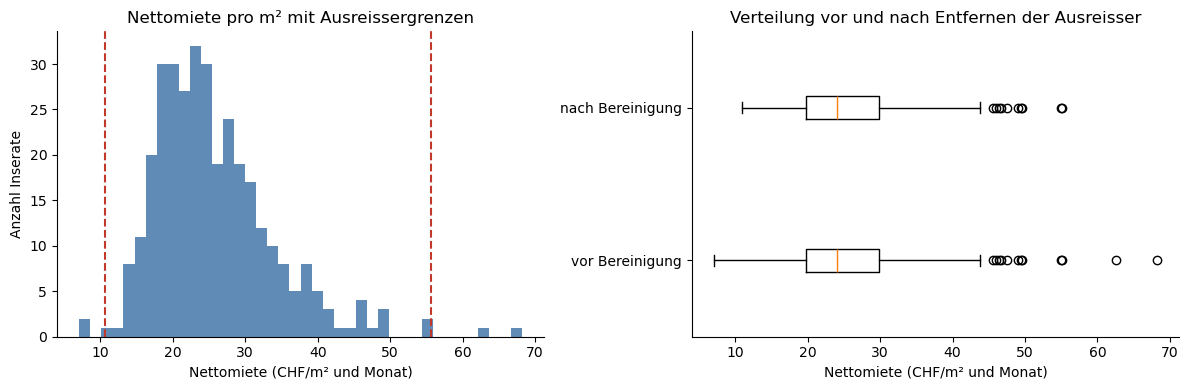

4 Ausreisser – Nettomiete/m² ausserhalb 10.6–55.6 CHF: 4 entfernt, 332 verbleibend


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["rent_net_per_m2"], bins=40, color="#3a6ea5", alpha=0.8)
for x in (lower, upper):
    axes[0].axvline(x, color="#c0392b", ls="--")
axes[0].set(title="Nettomiete pro m² mit Ausreissergrenzen", xlabel="Nettomiete (CHF/m² und Monat)", ylabel="Anzahl Inserate")

axes[1].boxplot([df["rent_net_per_m2"], df.loc[~is_outlier, "rent_net_per_m2"]], orientation="horizontal")
axes[1].set_yticks([1, 2], ["vor Bereinigung", "nach Bereinigung"])
axes[1].set(title="Verteilung vor und nach Entfernen der Ausreisser", xlabel="Nettomiete (CHF/m² und Monat)")

plt.tight_layout()
plt.show()

df = exclude(df, is_outlier, "4 Ausreisser", f"Nettomiete/m² ausserhalb {lower:.1f}–{upper:.1f} CHF")

*Hinweis zum Boxplot:* Der Boxplot verwendet die Tukey-Grenzen auf der normalen Skala und zeigt deshalb auch nach der Bereinigung noch einzelne Punkte über ca. 45 CHF/m². Auf der log-Skala, die wir für die Ausreisserregel verwenden, liegen diese Werte innerhalb der Grenzen. Es sind teure, aber plausible Wohnungen (v. a. Zug und Stadt Luzern).

## Anreicherung

Zusätzliche Spalten, die für die Analyse nützlich sind:

| Neue Spalte | Inhalt |
|---|---|
| `rent_net_per_m2` | Nettomiete pro m² und Monat (bereits in Schritt 4 erstellt) – Hauptzielgrösse |
| `rent_net_source` | ob die Nettomiete angegeben oder berechnet wurde (Schritt 1) |
| `charges_share_pct` | Anteil Nebenkosten an der Bruttomiete |
| `building_age` | Jahre seit Bau bzw. letzter Renovation |
| `room_class` | Zimmerkategorie (1–1.5, 2–2.5, 3–3.5, 4–4.5, 5+) für Gruppenvergleiche |
| `population_density_log` | log der Bevölkerungsdichte (die Dichte ist sehr schief verteilt) |
| `days_online` | Tage zwischen Veröffentlichung und letzter Sichtung (Hinweis auf Nachfrage) |

In [13]:
rent_gross_full = df["rent_gross"].fillna(df["rent_net"] + df["rent_charges"])
df["charges_share_pct"] = (df["rent_charges"] / rent_gross_full * 100).round(1)

last_year = df[["year_built", "year_renovated"]].max(axis=1)
df["building_age"] = (2026 - last_year).clip(lower=0).astype("Int64")

df["room_class"] = pd.cut(df["number_of_rooms"], bins=[0, 1.5, 2.5, 3.5, 4.5, 11],
                          labels=["1–1.5", "2–2.5", "3–3.5", "4–4.5", "5+"])

df["population_density_log"] = np.log(df["population_density_productive"])

df["days_online"] = (df["last_seen_at"] - df["published"]).dt.days

df[["rent_net_per_m2", "charges_share_pct", "building_age", "room_class", "population_density_log", "days_online"]].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rent_net_per_m2,332.0,NaN,NaN,NaN,25.582943,7.733199,11.0,19.768763,24.109782,29.843354,55.084746
charges_share_pct,327.0,NaN,NaN,NaN,10.431804,3.05721,4.8,8.25,9.8,12.25,28.9
building_age,222.0,<NA>,<NA>,<NA>,13.545045,19.11303,0.0,1.0,7.0,18.0,86.0
room_class,332,5,3–3.5,136,NaN,NaN,NaN,NaN,NaN,NaN,NaN
population_density_log,332.0,NaN,NaN,NaN,6.712738,1.112291,3.030134,5.809343,7.035709,8.021355,8.311988
days_online,332.0,NaN,NaN,NaN,43.692771,70.058212,0.0,9.0,18.0,48.0,535.0


## Format für die Analyse

Der Input hat über 150 Spalten (alle Felder der Flatfox-API). Für die Analyse behalten wir nur die benötigten Spalten in einer sinnvollen Reihenfolge: Identifikation > Miete > Wohnungsmerkmale > Lage > Gemeindeindikatoren > Erhebung. Die Zusammenführung mit den Gemeindeindikatoren ist bereits in `data_engineering_real_estate.ipynb` erfolgt.

In [14]:
FINAL_COLUMNS = [
    # Identifikation
    "pk", "source_url", "object_type",
    # Miete
    "rent_net", "rent_net_source", "rent_net_per_m2", "rent_charges", "rent_gross", "charges_share_pct",
    # Wohnungsmerkmale
    "surface_living", "number_of_rooms", "room_class", "floor", "year_built", "year_renovated", "building_age",
    "attribute_reported_balconygarden", "attribute_reported_lift", "attribute_reported_view",
    "attribute_reported_parkingspace", "attribute_reported_minergie",
    # Lage
    "latitude", "longitude", "gemeinde_bfs", "gemeinde_name", "kanton_geo",
    # Gemeindeindikatoren
    *indicator_columns, "population_density_log",
    # Erhebung
    "published", "first_seen_at", "last_seen_at", "scrape_count", "days_online",
]

clean = (df[FINAL_COLUMNS]
         .sort_values(["kanton_geo", "gemeinde_name", "pk"])
         .reset_index(drop=True))

print(f"Bereinigter Datensatz: {len(clean)} Inserate, {clean.shape[1]} Spalten, "
      f"{clean['gemeinde_bfs'].nunique()} Gemeinden")
clean.head()

Bereinigter Datensatz: 332 Inserate, 44 Spalten, 82 Gemeinden


,pk,source_url,object_type,rent_net,rent_net_source,rent_net_per_m2,rent_charges,rent_gross,charges_share_pct,surface_living,...,new_dwellings_per_1000_residents,single_family_buildings_pct,foreign_population_pct,net_migration_per_1000_residents,population_density_log,published,first_seen_at,last_seen_at,scrape_count,days_online
0,86419141,https://flatfox.ch/en/flat/vogelsang-6287-aesc...,APARTMENT,1950.0,angegeben,34.210526,190.0,NaN,8.9,57.0,...,17.9,57.0,17.2,45.0,5.839769,2026-10-04 18:05:49.326742+00:00,2026-10-18 12:14:52.635701+00:00,2026-10-24 09:39:01.857255+00:00,10,19
1,86469512,https://flatfox.ch/en/flat/alemannenweg-3-6287...,APARTMENT,2250.0,berechnet (brutto − Nebenkosten),22.500000,240.0,2490.0,9.6,100.0,...,17.9,57.0,17.2,45.0,5.839769,2026-10-20 19:28:32.150576+00:00,2026-10-21 19:25:50.227446+00:00,2026-10-24 09:39:01.857255+00:00,5,3
2,86349152,https://flatfox.ch/en/flat/unterdorf-12-6147-a...,APARTMENT,1200.0,angegeben,14.814815,150.0,1350.0,11.1,81.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-09-09 08:55:43.351266+00:00,2026-10-18 12:14:52.635701+00:00,2026-10-21 19:25:50.227446+00:00,6,42
3,86368528,https://flatfox.ch/en/flat/hintergasse-17-6147...,APARTMENT,1165.0,angegeben,14.382716,200.0,NaN,14.7,81.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-09-16 08:45:48.023625+00:00,2026-10-18 12:14:52.635701+00:00,2026-10-24 09:39:01.857255+00:00,10,38
4,86468238,https://flatfox.ch/en/flat/unterdorf-12-6147-a...,APARTMENT,1450.0,angegeben,13.425926,200.0,1650.0,12.1,108.0,...,0.0,50.5,13.4,-1.0,5.012633,2026-10-20 11:46:55.045648+00:00,2026-10-20 19:12:39.840560+00:00,2026-10-24 09:39:01.857255+00:00,6,3


## Ergebnis und Speichern

In [15]:
summary = pd.DataFrame(log, columns=["Schritt", "verbleibende Inserate"])
summary["entfernt"] = (-summary["verbleibende Inserate"].diff()).fillna(0).astype(int)
display(summary)

print("Inserate und Gemeinden pro Kanton:")
display(clean.groupby("kanton_geo", observed=True)
        .agg(Inserate=("pk", "size"), Gemeinden=("gemeinde_bfs", "nunique"))
        .reindex(CENTRAL_CANTONS))

,Schritt,verbleibende Inserate,entfernt
0,Ausgangslage,513,0
1,"0 Eingrenzung: keine Wohnung (WG-Zimmer, Haus)",477,36
2,1 Fehlende Werte: keine Nettomiete bestimmbar,348,129
3,1 Duplikate: gleiche Wohnung unter neuer ID,340,8
4,3 Wertebereich: Wohnfläche < 20 m²,337,3
5,3 Wertebereich: Fläche pro Zimmer < 8 m²,337,0
6,3 Wertebereich: Nettomiete ≤ 0 oder ≤ Nebenkosten,336,1
7,3 Wertebereich: Zimmerzahl ausserhalb 1–10,336,0
8,4 Ausreisser: Nettomiete/m² ausserhalb 10.6–55...,332,4


Inserate und Gemeinden pro Kanton:


,Inserate,Gemeinden
kanton_geo,,
LU,242,45
UR,3,3
SZ,48,17
OW,7,4
NW,5,4
ZG,27,9


In [16]:
excluded_df = pd.concat(excluded, ignore_index=True)

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUTPUT_FILE, index=False, encoding="utf-8-sig")
excluded_df.to_csv(EXCLUDED_FILE, index=False, encoding="utf-8-sig")

print(f"Gespeichert: {OUTPUT_FILE.relative_to(PROJECT_DIR)} ({len(clean)} Zeilen)")
print(f"Gespeichert: {EXCLUDED_FILE.relative_to(PROJECT_DIR)} ({len(excluded_df)} Zeilen)")

Gespeichert: data/data_processed/flatfox_rentals_clean.csv (332 Zeilen)
Gespeichert: data/data_processed/flatfox_rentals_excluded.csv (181 Zeilen)
